# Transport Balance

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import plotly.express as px
import numpy as np

pd.options.mode.chained_assignment = None

In [3]:
# Data preparation - read all excel files and sheets
path_files = r"C:\Users\rnarendar\Fraunhofer\DeV-KopSys-2 - Globale ESA\01_countries\DevKopSysII_v2.0\results_v0.2_deadline_October\energy_base_totals\xlsx_per_country"
files = [
    ("demands_MA_v2.xlsx", "csv_pypsa"),
    ("demands_CL_v2.xlsx", "csv_pypsa"),
    ("demands_EG_v2.xlsx", "csv_pypsa"),
    ("demands_ZA_v2.xlsx", "csv_pypsa")
]

dfs = []
for file, sheet in files:
    file_path = os.path.join(path_files, file)
    df = pd.read_excel(file_path, sheet_name=sheet)
    dfs.append(df)

# Concatenate all DataFrames into one
df = pd.concat(dfs, ignore_index=True)
df.set_index(['scenario',"country"], inplace=True)
df.drop(index = [("base_2030")], inplace=True)

# select columns related to transport
columns_transport = [
    "total road ev",
    "total road fcev",
    "total road ice",
    "road biomass",
    "total domestic aviation",
    "total domestic navigation",
    "total navigation hydrogen",
    "total navigation oil",
    "total navigation ammonia",
    "total navigation biomass",
    "total aviation biomass",
    "total international aviation",
    "total international navigation",
    "total rail hydrogen",
    "electricity rail",
    "total rail",
    # "international aviation e-fuel",
]

df_transport= df[columns_transport]

df_transport.rename(columns={
    "total road ev": "road electricity",
    "total road fcev": "road hydrogen",
    "total road ice": "road liq. hydrocarbon",
    "road biomass": "road biomass", # substract this from road hydrocarbon
    "total domestic aviation": "dom. aviation",
    "total domestic navigation": "dom. maritime",
    "total navigation hydrogen": "dom. maritime hydrogen",
    "total navigation oil":"dom. maritime hydrocarbon",
    "total navigation biomass": "dom. maritime biomass",
    "total aviation biomass": "dom. aviation biomass",
    "total navigation ammonia": "dom. maritime ammonia",
    "total international aviation": "int. aviation",
    "total international navigation": "int. maritime",
    "total rail hydrogen": "rail hydrogen",
    "electricity rail": "rail electricity",
    }, inplace=True)

# calculate correctly the road liquid hydrocarbon demand
df_transport["road liq. hydrocarbon"] = df_transport["road liq. hydrocarbon"] - df_transport["road biomass"]
# df_transport["dom. maritime hydrocarbon"] = df_transport["dom. maritime"] - df_transport["dom. maritime hydrogen"] - df_transport["dom. maritime ammonia"]
df_transport["rail liq. hydrocarbons"] = df_transport["total rail"] - df_transport["rail hydrogen"] - df_transport["rail electricity"]
df_transport["dom. aviation liq. hydrocarbon"] = df_transport["dom. aviation"] - df_transport["dom. aviation biomass"]
# drop all unnecessary columns
df_transport.drop(columns=["dom. maritime","total rail","dom. aviation"], inplace=True)


# Define mapping for each column: (mode, carrier)
column_map = {
    "road electricity": ("road", "electricity"),
    "road hydrogen": ("road", "hydrogen"),
    "road liq. hydrocarbon": ("road", "liq. hydrocarbons"),
    "road biomass": ("road", "biomass"),
    "dom. aviation biomass": ("aviation", "biomass"),
    "dom. aviation liq. hydrocarbon": ("aviation", "liq. hydrocarbons"),
    "int. aviation": ("int. aviation", "liq. hydrocarbons"),
    "dom. maritime hydrogen": ("maritime", "hydrogen"),
    "dom. maritime hydrocarbon": ("maritime", "liq. hydrocarbons"),
    "dom. maritime biomass": ("maritime", "biomass"),
    "dom. maritime ammonia": ("maritime", "ammonia"),
    "int. maritime": ("int. maritime", "liq. hydrocarbons"),
    "rail hydrogen": ("rail", "hydrogen"),
    "rail electricity": ("rail", "electricity"),
    "rail liq. hydrocarbons": ("rail", "liq. hydrocarbons"),
}


# Reindex columns to MultiIndex with mode first, carrier second
new_columns = []
for col in df_transport.columns:
    if col in column_map:
        new_columns.append(column_map[col])
    else:
        # If not mapped, keep original name as mode, and set carrier as 'Other'
        new_columns.append((col, "Other"))
df_transport.columns = pd.MultiIndex.from_tuples(new_columns)

# drop scenarios
df_transport = df_transport.drop(df_transport.index[df_transport.index.get_level_values("scenario") == "base"])


# Convert wide MultiIndex DataFrame to long format
long_df = (
    df_transport
    .stack(level=[0, 1])  # Stack mode and carrier columns
    .reset_index()        # Convert index to columns
    .rename(columns={
        0: "value",
        "level_2": "mode",
        "level_3": "carrier"})  # Rename the value column
)

# Prepare mode_grouped column with new categories for grouped plotting
mode_grouped_order = ["road", "rail", "aviation (all)", "maritime (all)"]
long_df_grouped = long_df.copy()
long_df_grouped["mode_grouped"] = long_df_grouped["mode"].astype(str)
long_df_grouped.loc[long_df_grouped["mode"].str.contains("aviation"), "mode_grouped"] = "aviation (all)"
long_df_grouped.loc[long_df_grouped["mode"].str.contains("maritime"), "mode_grouped"] = "maritime (all)"
long_df_grouped["mode_grouped"] = pd.Categorical(long_df_grouped["mode_grouped"], categories=mode_grouped_order, ordered=True)
long_df_grouped

# fix the several values with same indexes
long_df_grouped_sum = (
    long_df_grouped
    .groupby(["country", "scenario", "mode_grouped", "carrier"], as_index=False)["value"]
    .sum()
)
long_df_grouped_sum[long_df_grouped_sum["country"] == "CL"].head(20)

C:\Users\rnarendar\AppData\Local\Temp\ipykernel_29212\547366898.py:19: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  df.drop(index = [("base_2030")], inplace=True)
C:\Users\rnarendar\AppData\Local\Temp\ipykernel_29212\547366898.py:108: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  .stack(level=[0, 1])  # Stack mode and carrier columns
C:\Users\rnarendar\AppData\Local\Temp\ipykernel_29212\547366898.py:128: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["country", "scenario", "mode_grouped", "carrier"], as_index=False

,country,scenario,mode_grouped,carrier,value
0,CL,EL_2030,road,ammonia,0.000000
1,CL,EL_2030,road,biomass,0.000000
2,CL,EL_2030,road,electricity,4.606434
3,CL,EL_2030,road,hydrogen,0.000000
4,CL,EL_2030,road,liq. hydrocarbons,89.296922
5,CL,EL_2030,rail,ammonia,0.000000
6,CL,EL_2030,rail,biomass,0.000000
7,CL,EL_2030,rail,electricity,0.342911
8,CL,EL_2030,rail,hydrogen,0.000000
9,CL,EL_2030,rail,liq. hydrocarbons,0.414542


In [4]:
transport_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
}
country_dic = {"CL":"Chile","EG":"Egypt","MA":"Morocco","ZA":"South Africa"}

def plot_per_country(df, facet_gap=0.08, ytick_size=12, fig_width=1100, fig_height=420, bargap=0.15):
    figs = {}
    mode_order = ["road", "maritime (all)", "aviation (all)", "rail"]
    carrier_order = ['electricity','hydrogen','liq.hydrocarbons','biomass','ammonia']
    scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050']

    for cty, d in df.groupby("country"):
        full_name = country_dic.get(cty, cty)
        fig = px.bar(
            d,
            x="scenario",
            y="value",
            color="carrier",
            facet_col="mode_grouped",
            facet_col_spacing=facet_gap,
            category_orders={"mode_grouped": mode_order, "carrier": carrier_order, "scenario": scenario_order},
            color_discrete_map=transport_colors,   # <-- custom colors here
            barmode="stack",
            labels={"value": "Final end use energy demand (TWh)", "carrier": "Carrier"},
            title=f"Final energy by mode, scenario, and carrier — {full_name}",
        )
        fig.update_yaxes(matches=None, showticklabels=True, ticks="outside",
                         automargin=True, tickfont=dict(size=ytick_size))
        fig.update_layout(bargap=bargap, width=fig_width, height=fig_height,
                          margin=dict(l=90, r=20, t=60, b=40), legend_title_text="Carrier")
        figs[cty] = fig

        # only one scenario x-axis title
        fig.update_xaxes(title_text=None)
        # fig.add_annotation(
        #     x=-0.1, y=-0.08, xref="paper", yref="paper",
        #     showarrow=False, text="Scenario"
        # )
        fig.for_each_annotation(lambda a: a.update(text=a.text.split("=", 1)[-1]))
        fig.for_each_xaxis(lambda ax: ax.update(categoryorder="array", categoryarray=scenario_order))


    return figs

figs = plot_per_country(long_df_grouped_sum)

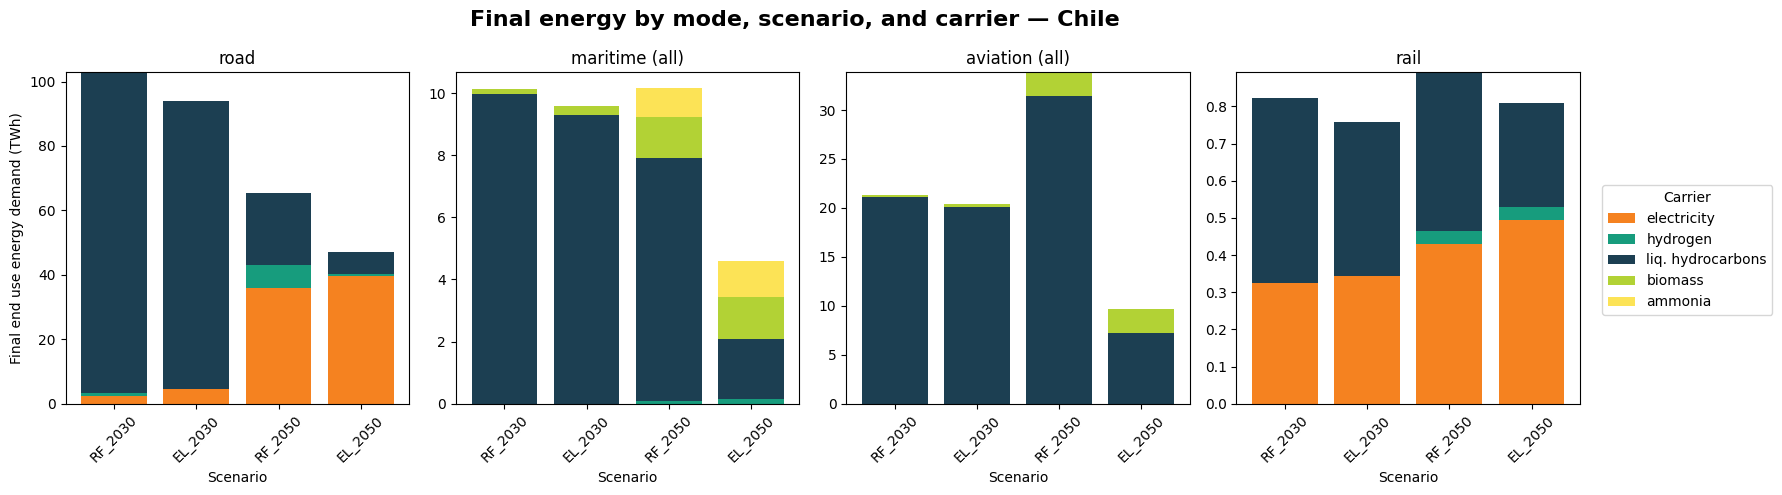

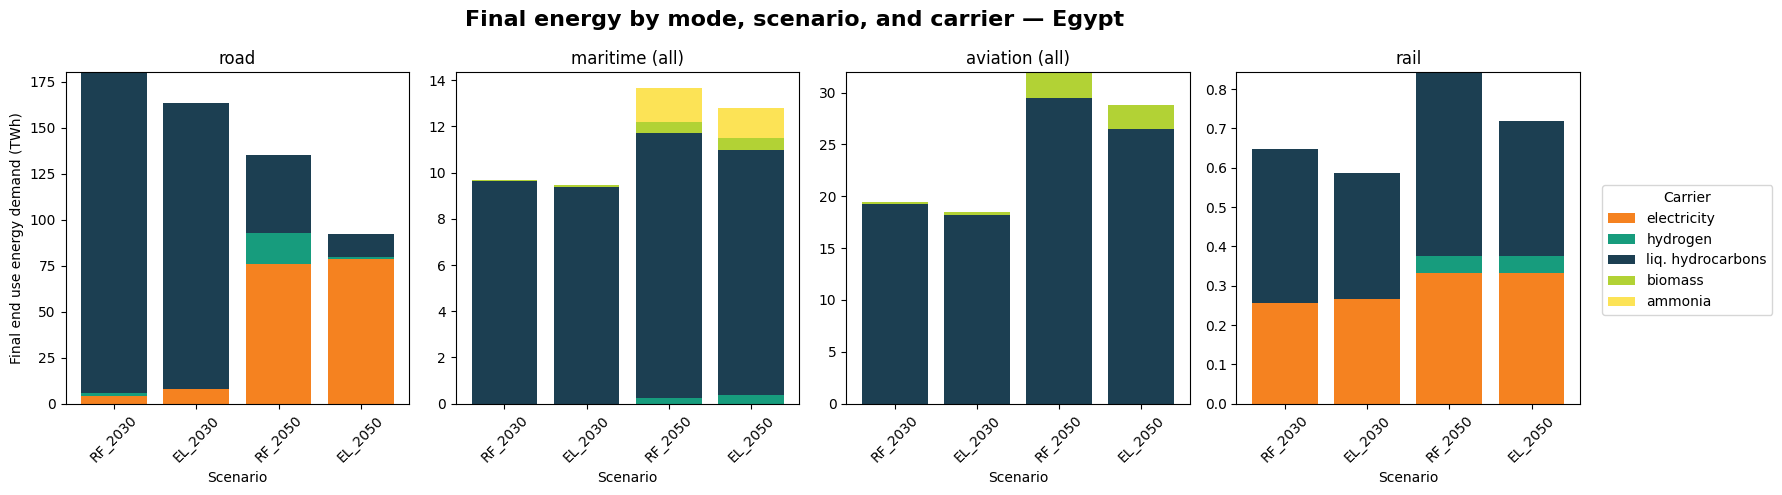

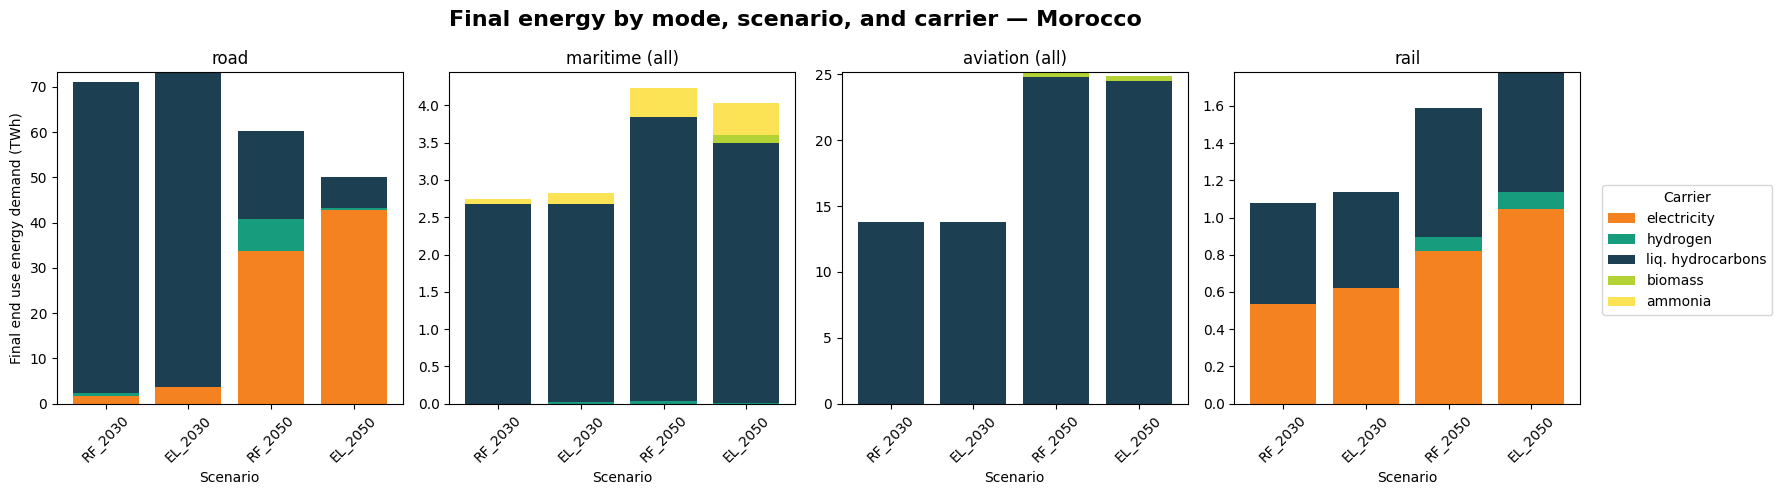

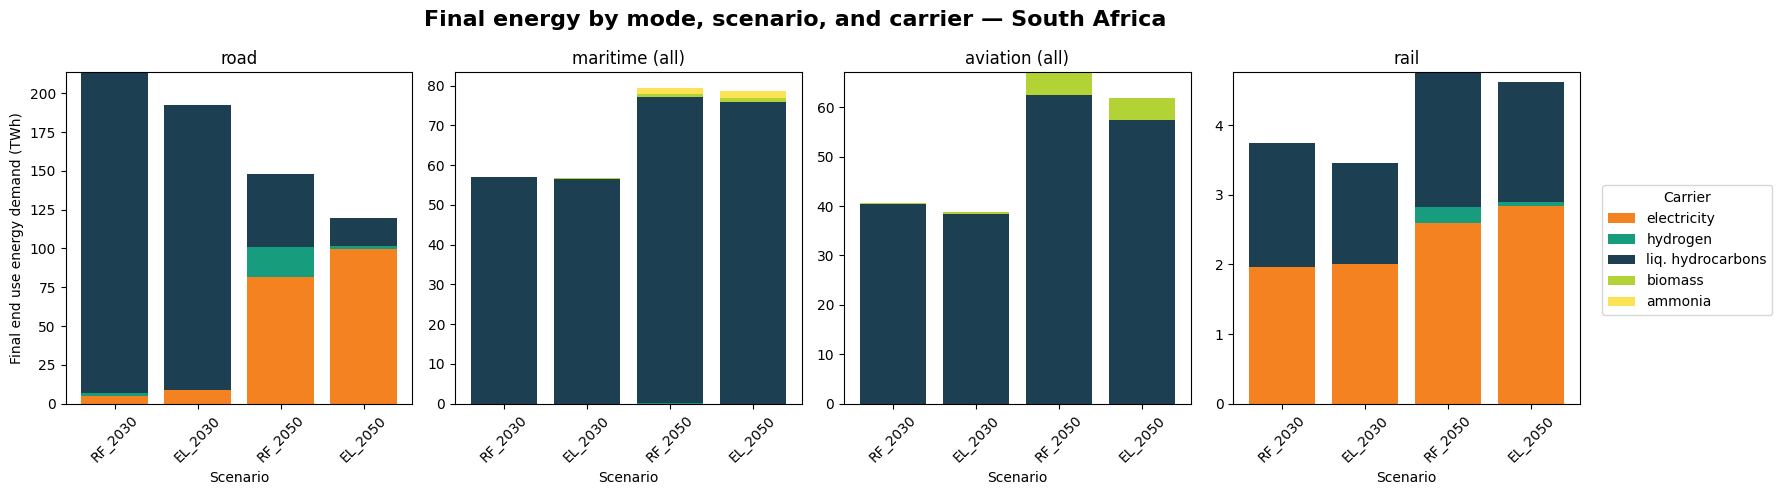

In [5]:
mode_order = ["road", "maritime (all)", "aviation (all)", "rail"]
carrier_order = ['electricity', 'hydrogen', 'liq. hydrocarbons', 'biomass', 'ammonia']
scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050']
country_dic = {"CL":"Chile","EG":"Egypt","MA":"Morocco","ZA":"South Africa"}


for cty, d in long_df_grouped_sum.groupby("country"):
    full_name = country_dic.get(cty, cty)
    fig, axs = plt.subplots(1, len(mode_order), figsize=(16, 5), sharey=False)
    for i, mode in enumerate(mode_order):
        ax = axs[i]
        d_mode = d[d["mode_grouped"] == mode]
        d_mode = d_mode.copy()
        d_mode['scenario'] = pd.Categorical(d_mode['scenario'], categories=scenario_order, ordered=True)
        pivot = d_mode.pivot_table(index='scenario', columns='carrier', values='value', aggfunc='sum', observed=False).fillna(0)
        bottom = None
        for carrier in carrier_order:
            values = pivot[carrier] if carrier in pivot.columns else [0]*len(pivot)
            ax.bar(pivot.index, values, bottom=bottom, color=transport_colors.get(carrier, "#cccccc"), label=carrier)
            bottom = values if bottom is None else bottom + values
        ax.set_title(mode)
        ax.set_xlabel('Scenario')
        if i == 0:
            ax.set_ylabel('Final end use energy demand (TWh)')
        ax.tick_params(axis='x', rotation=45)
    fig.suptitle(f"Final energy by mode, scenario, and carrier — {full_name}", fontsize=16, weight='bold')
    fig.legend(carrier_order, title="Carrier", loc='center left', bbox_to_anchor=(1.0, 0.5))
    plt.tight_layout()
    plt.show()

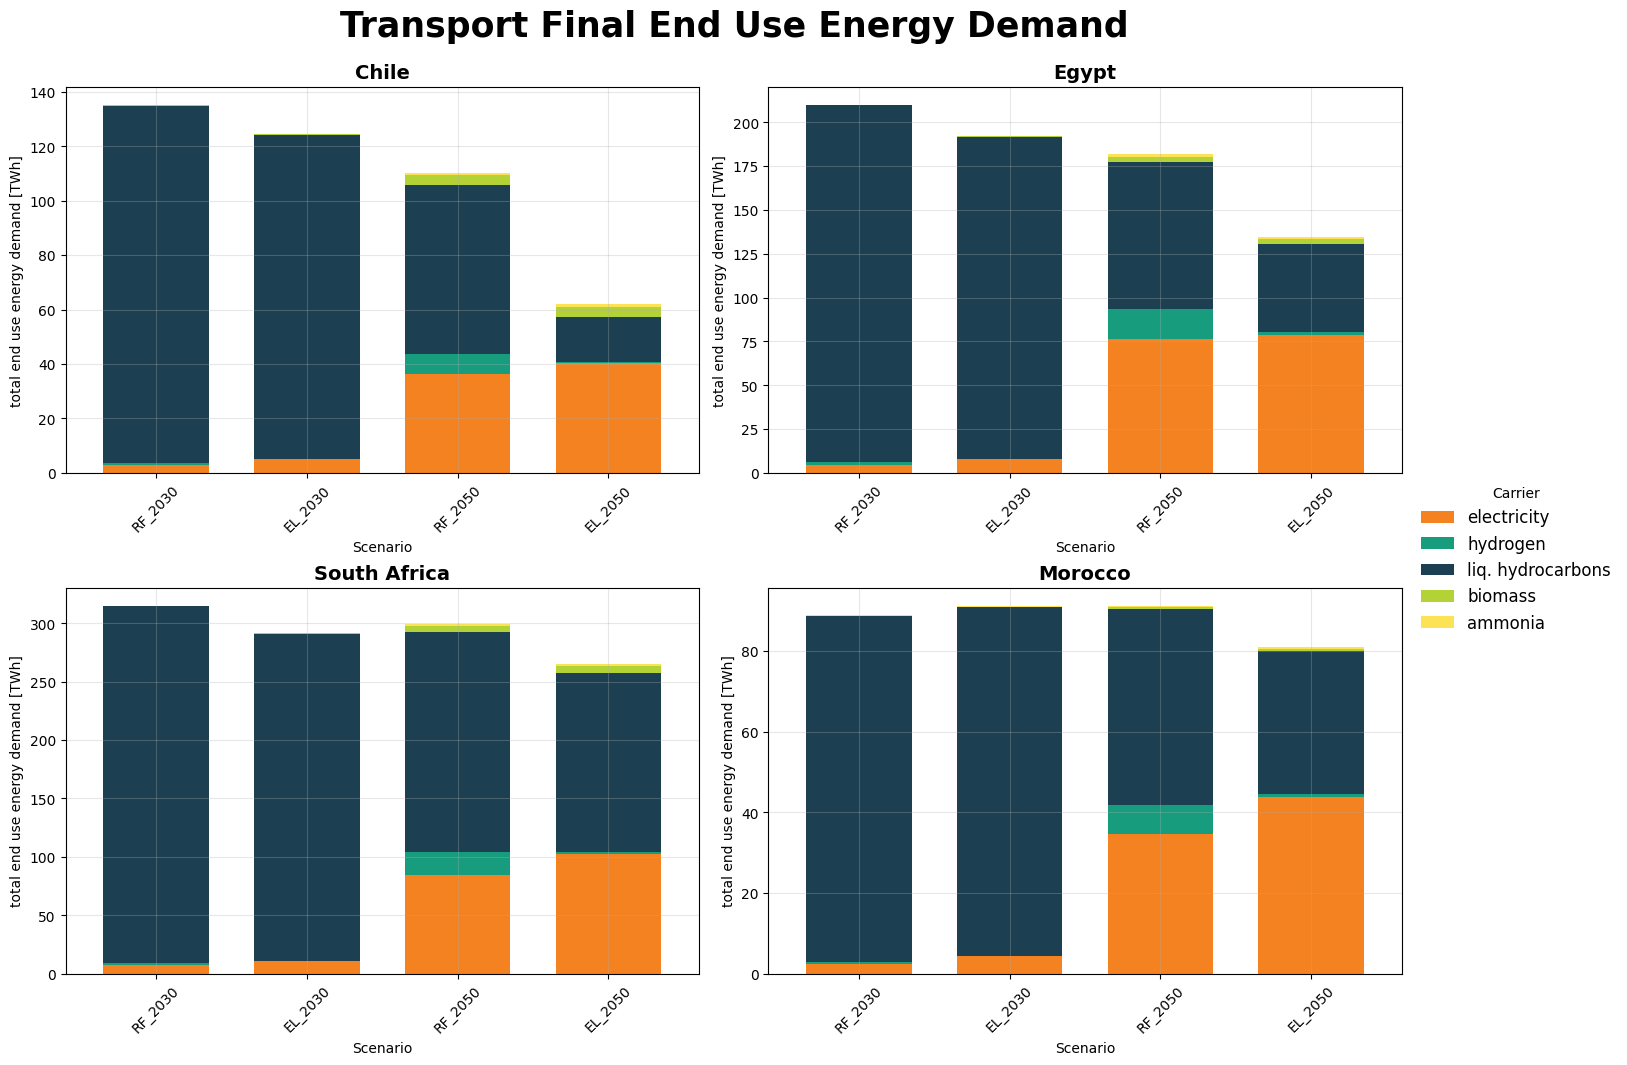

In [6]:
# Define color mapping for carriers
transport_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
}
carrier_order = ['electricity', 'hydrogen', 'liq. hydrocarbons', 'biomass', 'ammonia']
scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050']
country_dic = {"CL": "Chile", "EG": "Egypt", "MA": "Morocco", "ZA": "South Africa"}

# Aggregate all modes for each country, scenario, and carrier
df_agg = (
    long_df_grouped
    .groupby(["country", "scenario", "carrier"], as_index=False)["value"]
    .sum()
)

def plot_transport_bar_agg(df_agg, country_code, ax):
    df_country = df_agg[df_agg['country'] == country_code].copy()
    df_country['scenario'] = pd.Categorical(df_country['scenario'], categories=scenario_order, ordered=True)
    df_pivot = df_country.pivot(index='scenario', columns='carrier', values='value')
    df_pivot = df_pivot[carrier_order]  # Ensure column order
    colors = [transport_colors[c] for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight='bold')
    ax.set_xlabel('Scenario')
    ax.set_ylabel('total end use energy demand [TWh]')
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

plot_transport_bar_agg(df_agg, 'CL', axs[0, 0])
plot_transport_bar_agg(df_agg, 'EG', axs[0, 1])
plot_transport_bar_agg(df_agg, 'ZA', axs[1, 0])
plot_transport_bar_agg(df_agg, 'MA', axs[1, 1])

fig.suptitle('Transport Final End Use Energy Demand', fontsize=25, weight='bold', y=1.05, x=0.52)

handles, labels = axs[0,0].get_legend_handles_labels()
fig.legend(handles, labels, title='Carrier', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
fig.savefig("Transport_demand_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()

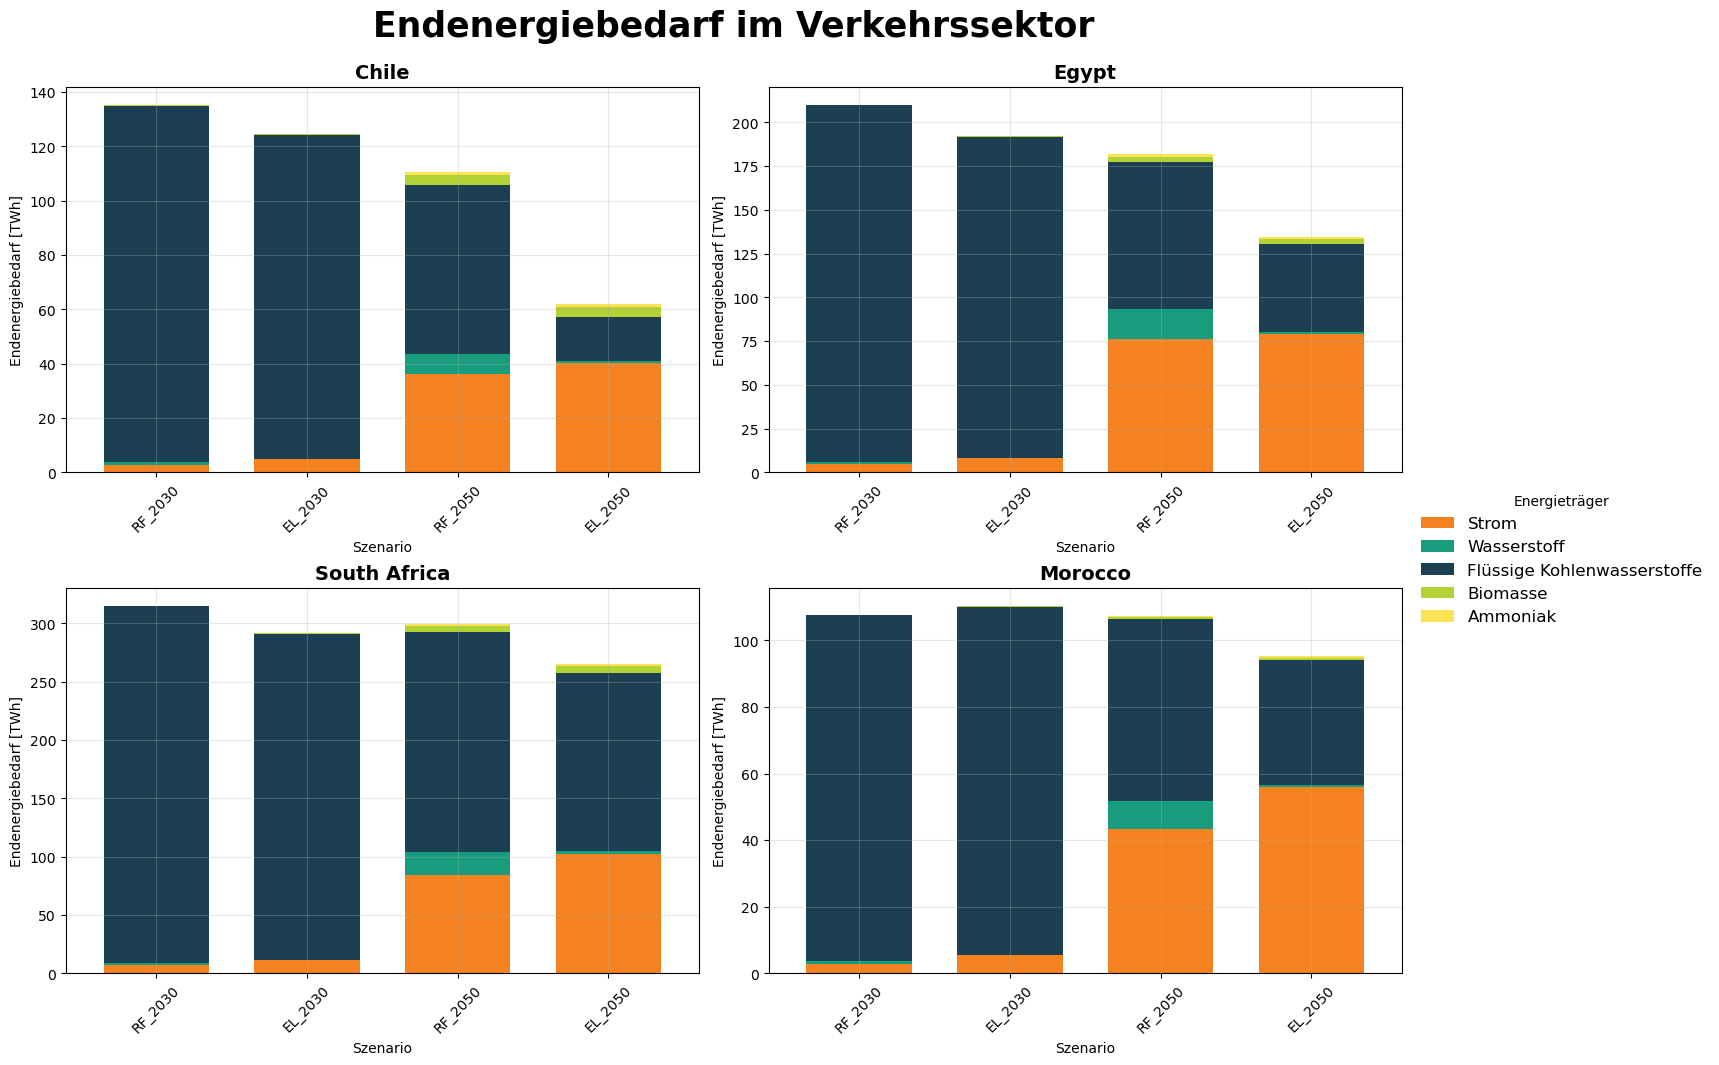

In [9]:
# German mapping for carriers
carrier_legend_de = {
    'electricity': 'Strom',
    'hydrogen': 'Wasserstoff',
    'liq. hydrocarbons': 'Flüssige Kohlenwasserstoffe',
    'biomass': 'Biomasse',
    'ammonia': 'Ammoniak'
}

# Define color mapping for carriers
transport_colors = {
    'liq. hydrocarbons': '#1c3f52',
    'electricity': '#f58220',
    'hydrogen': '#179c7d',
    'biomass': '#b2d235',
    'ammonia': '#fce356',
}
carrier_order = ['electricity', 'hydrogen', 'liq. hydrocarbons', 'biomass', 'ammonia']
scenario_order = ['RF_2030', 'EL_2030', 'RF_2050', 'EL_2050']
country_dic = {"CL": "Chile", "EG": "Egypt", "MA": "Morocco", "ZA": "South Africa"}

y_axis_label_de = 'Endenergiebedarf [TWh]'

# Aggregate all modes for each country, scenario, and carrier
df_agg = (
    long_df_grouped
    .groupby(["country", "scenario", "carrier"], as_index=False)["value"]
    .sum()
)

def plot_transport_bar_agg(df_agg, country_code, ax):
    df_country = df_agg[df_agg['country'] == country_code].copy()
    df_country['scenario'] = pd.Categorical(df_country['scenario'], categories=scenario_order, ordered=True)
    df_pivot = df_country.pivot(index='scenario', columns='carrier', values='value')
    df_pivot = df_pivot[carrier_order]  # Ensure column order
    colors = [transport_colors[c] for c in df_pivot.columns]
    df_pivot.plot.bar(ax=ax, color=colors, width=0.7, legend=False, stacked=True)
    ax.set_title(country_dic.get(country_code, country_code), fontsize=14, weight='bold')
    ax.set_xlabel('Szenario')  # German for Scenario
    ax.set_ylabel(y_axis_label_de)
    ax.grid(alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

fig, axs = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

plot_transport_bar_agg(df_agg, 'CL', axs[0, 0])
plot_transport_bar_agg(df_agg, 'EG', axs[0, 1])
plot_transport_bar_agg(df_agg, 'ZA', axs[1, 0])
plot_transport_bar_agg(df_agg, 'MA', axs[1, 1])

fig.suptitle('Endenergiebedarf im Verkehrssektor', fontsize=25, weight='bold', y=1.05, x=0.52)

handles, labels = axs[0,0].get_legend_handles_labels()
labels_de = [carrier_legend_de.get(label, label) for label in labels]
fig.legend(handles, labels_de, title='Energieträger', loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize='large', frameon=False)
fig.savefig("Transport_demand_bar_plot.png", dpi=300, bbox_inches='tight')
plt.show()